Model Selection and Justification (15%)

• Choose appropriate machine learning models for the task (e.g., classification, regression)

* . Consider multiple models
• Apply hyperparameter tuning techniques.
* • Compare multiple models and make a justified choice for the final model (the justification is essential
* and should be completely written down in the notebook!

In [ ]:
import os, math, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [ ]:
# Optional XGBoost
try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except Exception:
    HAS_XGB = False

print("XGBoost available:", HAS_XGB)


In [43]:
# ============================================================
# Load already-cleaned data
# ============================================================
df = pd.read_csv("data/melbourne_housing_cleaned_v2.csv")
print("Shape:", df.shape)
df.head()

Shape: (3895, 31)


,Distance,Bedroom,Bathroom,Car,YearBuilt,Latitude,Longtitude,Propertycount,Log_Landsize,Log_BuildingArea,...,Regionname_Northern Metropolitan,Regionname_Northern Victoria,Regionname_South-Eastern Metropolitan,Regionname_Southern Metropolitan,Regionname_Western Metropolitan,Regionname_Western Victoria,PropertyAge,Log_Price_Per_SqM,Log_TotalArea,Is_CBD
0,5.3,3.0,1.0,2.0,1970.0,-37.806498,144.992667,11364.0,6.246107,4.317488,...,1.0,0.0,0.0,0.0,0.0,0.0,47.0,9.102124,6.380123,0
1,13.8,3.0,1.0,2.0,1960.0,-37.912970,145.073500,10969.0,6.246107,5.003946,...,0.0,0.0,0.0,1.0,0.0,0.0,57.0,9.128307,6.498282,0
2,12.0,3.0,1.0,1.0,1950.0,-37.729240,145.029810,21650.0,5.141664,4.859812,...,1.0,0.0,0.0,0.0,0.0,0.0,67.0,8.465702,5.700444,0
3,14.5,3.0,1.0,2.0,1960.0,-37.806498,144.992667,851.0,6.246107,5.003946,...,1.0,0.0,0.0,0.0,0.0,0.0,57.0,8.148265,6.498282,0
4,4.5,2.0,2.0,2.0,1890.0,-37.847600,144.989200,7717.0,5.476464,5.036953,...,0.0,0.0,0.0,1.0,0.0,0.0,127.0,9.557953,5.971262,1


In [44]:
# Final selected features during feature engineering
final_features = [
    'Distance',
    'Bedroom',
    'Bathroom',
    'CouncilArea_enc',
    'Type_u',
    'Regionname_Southern Metropolitan',
    'Log_TotalArea',
    'Log_Landsize',
    'Log_BuildingArea',
    'PropertyAge',
    'Propertycount',
    'YearBuilt',
    'Is_CBD'
]


In [45]:
# Define final dataset
X = df[final_features]
y = df['Log_Price']
#X = df.drop(columns=["Log_Price"])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [46]:
# ---------- PREPROCESSORS ----------
# Standard numeric pipeline (for most models)
standard_Pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numeric pipeline with polynomial expansion (degree=2) for the Polynomial Regression candidate
# Warning: this can get large with many numeric features; degree=2 is a reasonable compromise
poly_Pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False))
])


In [47]:
# ---------- METRICS ----------
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    # Safe MAPE (guard against zeros)
    eps = 1e-12
    mape = np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), eps, None))) * 100.0
    return {"R2": r2, "MAE": mae, "RMSE": rmse, "MAPE_%": mape}

# ---------- CANDIDATE MODELS + SEARCH SPACES ----------
models = {}

# 1) Linear Regression (baseline)
models["Linear Regression"] = {
    "estimator": Pipeline([
        ("preprocess", standard_Pipeline),
        ("model", LinearRegression())
    ]),
    "param_distributions": {},
    "n_iter": 1
}

# 2) Ridge Regression (regularized linear)
models["Ridge Regression"] = {
    "estimator": Pipeline([
        ("preprocess", standard_Pipeline),
        ("model", Ridge(random_state=42))
    ]),
    "param_distributions": {
        "model__alpha": np.logspace(-2, 2, 20)  # 0.01 to 100
    },
    "n_iter": 15
}

# 3) Polynomial Regression (degree=2 over numeric features)
models["Polynomial (deg=2)"] = {
    "estimator": Pipeline([
        ("preprocess", poly_Pipeline),
        ("model", LinearRegression())
    ]),
    "param_distributions": {},  # no model hyperparams; degree fixed in preprocessor_poly
    "n_iter": 1
}

# 4) Decision Tree
models["Decision Tree"] = {
    "estimator": Pipeline([
        ("preprocess", standard_Pipeline),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),
    "param_distributions": {
        "model__max_depth": [None] + list(range(3, 21)),
        "model__min_samples_split": [2, 5, 10, 20, 50],
        "model__min_samples_leaf": [1, 2, 5, 10, 20]
    },
    "n_iter": 20
}

# 5) KNN Regressor
models["KNN Regressor"] = {
    "estimator": Pipeline([
        ("preprocess", standard_Pipeline),
        ("model", KNeighborsRegressor())
    ]),
    "param_distributions": {
        "model__n_neighbors": list(range(3, 51, 2)),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]  # Manhattan vs Euclidean
    },
    "n_iter": 20
}

# 6) SVR (RBF)
models["SVR (RBF)"] = {
    "estimator": Pipeline([
        ("preprocess", standard_Pipeline),
        ("model", SVR(kernel="rbf"))
    ]),
    "param_distributions": {
        "model__C": np.logspace(-1, 3, 20),
        "model__gamma": np.logspace(-4, 0, 20),
        "model__epsilon": np.logspace(-3, 0, 10)
    },
    "n_iter": 20
}

# 7) Random Forest
models["Random Forest"] = {
    "estimator": Pipeline([
        ("preprocess", standard_Pipeline),
        ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
    ]),
    "param_distributions": {
        "model__n_estimators": [200, 400, 600],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },
    "n_iter": 20
}

# 8) Gradient Boosting
models["Gradient Boosting"] = {
    "estimator": Pipeline([
        ("preprocess", standard_Pipeline),
        ("model", GradientBoostingRegressor(random_state=42))
    ]),
    "param_distributions": {
        "model__n_estimators": [100, 200, 300],
        "model__learning_rate": np.linspace(0.01, 0.2, 10),
        "model__max_depth": [2, 3, 4],
        "model__subsample": [0.8, 1.0],
        "model__min_samples_split": [2, 5, 10]
    },
    "n_iter": 20
}

# 9) Lasso Regression (regularized linear)
models["Lasso Regression"] = {
    "estimator": Lasso(random_state=42, max_iter=10000),
    "param_distributions": {
        "alpha": np.logspace(-4, 1, 20)  # Controls regularization strength
    },
    "n_iter": 15
}

print("Candidates:", list(models.keys()))

Candidates: ['Linear Regression', 'Ridge Regression', 'Polynomial (deg=2)', 'Decision Tree', 'KNN Regressor', 'SVR (RBF)', 'Random Forest', 'Gradient Boosting', 'Lasso Regression']



=== Training: Linear Regression ===

=== Training: Ridge Regression ===

=== Training: Polynomial (deg=2) ===

=== Training: Decision Tree ===

=== Training: KNN Regressor ===

=== Training: SVR (RBF) ===

=== Training: Random Forest ===

=== Training: Gradient Boosting ===

=== Training: Lasso Regression ===

================ RESULTS (sorted by Test R²) ================
                Model     CV_R2   Test_R2  Test_MAE  Test_RMSE  Test_MAPE_%
0   Gradient Boosting  0.778703  0.775096  0.180837   0.243619     1.321721
1       Random Forest  0.760626  0.758667  0.188217   0.252360     1.377635
2           SVR (RBF)  0.743591  0.748442  0.193183   0.257651     1.412197
3       KNN Regressor  0.715883  0.738215  0.198494   0.262836     1.455063
4  Polynomial (deg=2)       NaN  0.728164  0.199657   0.267835     1.461011
5       Decision Tree  0.682673  0.685186  0.215311   0.288231     1.574458
6    Lasso Regression  0.667967  0.670005  0.228895   0.295098     1.679346
7   Linear Regres

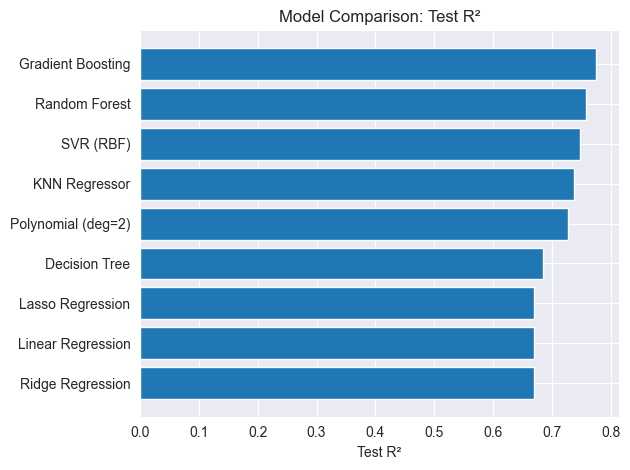

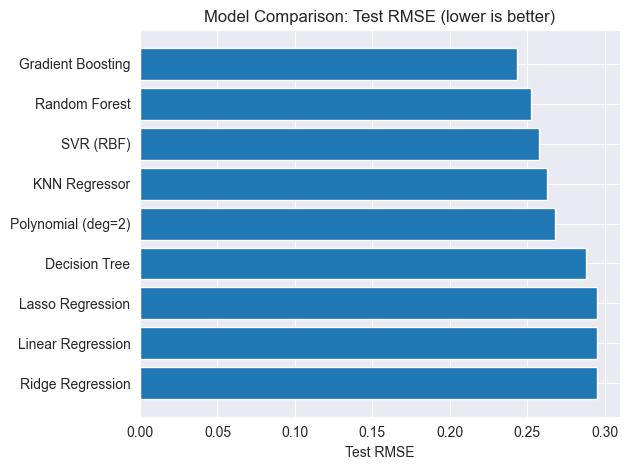


================ BEST MODEL ================
Name: Gradient Boosting
Metrics on Test set: {'R2': 0.7750961189816473, 'MAE': 0.1808373130625237, 'RMSE': np.float64(0.24361921729987074), 'MAPE_%': np.float64(1.3217205225974797)}


In [48]:
# ---------- RUN MODEL SELECTION ----------
cv = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []
best_overall = {"name": None, "estimator": None, "score": -np.inf, "metrics": None}

for name, spec in models.items():
    print(f"\n=== Training: {name} ===")
    estimator = spec["estimator"]
    dist = spec["param_distributions"]
    n_iter = spec["n_iter"]

    if len(dist) == 0:
        # Fit once (no hyperparameters)
        estimator.fit(X_train, y_train)
        y_pred = estimator.predict(X_test)
        mets = regression_metrics(y_test, y_pred)
        cv_score = np.nan
        best_estimator = estimator
    else:
        search = RandomizedSearchCV(
            estimator=estimator,
            param_distributions=dist,
            n_iter=n_iter,
            scoring="r2",
            cv=cv,
            n_jobs=-1,
            random_state=42,
            verbose=0
        )
        search.fit(X_train, y_train)
        best_estimator = search.best_estimator_
        y_pred = best_estimator.predict(X_test)
        mets = regression_metrics(y_test, y_pred)
        cv_score = search.best_score_

    rows.append({
        "Model": name,
        "CV_R2": cv_score,
        "Test_R2": mets["R2"],
        "Test_MAE": mets["MAE"],
        "Test_RMSE": mets["RMSE"],
        "Test_MAPE_%": mets["MAPE_%"]
    })

    if mets["R2"] > best_overall["score"]:
        best_overall = {"name": name, "estimator": best_estimator, "score": mets["R2"], "metrics": mets}

# ---------- RESULTS TABLE ----------
results_df = pd.DataFrame(rows)
results_df_sorted = results_df.sort_values("Test_R2", ascending=False).reset_index(drop=True)

print("\n================ RESULTS (sorted by Test R²) ================")
print(results_df_sorted)

# ---------- PLOTS ----------
# Note: one chart per figure; no custom colors
plt.figure()
srt = results_df.sort_values("Test_R2", ascending=True)
plt.barh(srt["Model"], srt["Test_R2"])
plt.xlabel("Test R²")
plt.title("Model Comparison: Test R²")
plt.tight_layout()
plt.show()

plt.figure()
srt_rmse = results_df.sort_values("Test_RMSE", ascending=False)
plt.barh(srt_rmse["Model"], srt_rmse["Test_RMSE"])
plt.xlabel("Test RMSE")
plt.title("Model Comparison: Test RMSE (lower is better)")
plt.tight_layout()
plt.show()

# ---------- BEST MODEL SUMMARY ----------
print("\n================ BEST MODEL ================")
print("Name:", best_overall["name"])
print("Metrics on Test set:", best_overall["metrics"])